# Acoustic Feature Analysis — HUSTmotor

### Random Forest baseline using 11 engineered acoustic features

**Université de technologie de Compiègne (UTC) · Motor Fault Diagnosis Workshop**

This notebook extends the acoustic-only HUSTmotor experiments by evaluating **11 time-domain acoustic features** as inputs to a **Random Forest classifier** under **leave-one-speed-out domain generalization**.

Our previous experiments used the 1,024-point acoustic waveform with a 1D CNN. This experiment instead asks:

> **Can 11 interpretable acoustic descriptors identify six motor conditions at an unseen operating speed? Are waveform-shape descriptors more transferable than amplitude-related descriptors?**

**Scope:** Acoustic modality only. We do **not** feed the Random Forest into the CNN here. If these features are useful, a separate future experiment could build a two-branch CNN + engineered-feature model.

**Project links**

- [Acoustic CNN repository](https://github.com/Sofianopoulou/hustmotor-acoustic-fault-diagnosis)
- [Shared HUSTmotor preprocessing and usage guide](https://github.com/Genti24-bit/ISCF_Project/blob/main/USAGE.md)
- [Dataset release v1.3](https://github.com/Genti24-bit/ISCF_Project/releases/tag/v1.3)
- [Zhao et al. (2025) reference paper](https://doi.org/10.1016/j.engappai.2025.112559)

## 1. Research design and experimental protocol

### Why use a Random Forest?

A Random Forest is a **standalone supervised classifier** that can learn nonlinear relationships from an 11-dimensional tabular input. It provides a simple, interpretable point of comparison with the waveform-based CNN. We can also inspect feature reliance with **permutation importance on source-validation data**.

| Experiment | Input | Classifier | Purpose |
|---|---|---|---|
| Previous baseline | Acoustic window `(1, 1024)` | 1D CNN | Learn representations from waveform |
| **Current experiment** | 11 acoustic statistics `(11,)` | **Random Forest** | Evaluate engineered features independently |
| Future possibility | Waveform + engineered statistics | CNN + separate dense branch | Test representation fusion |

### Leave-one-speed-out tasks

| Task | Source (train + validation) speeds | Held-out target speed |
|---|---|---|
| 9 | 10, 20, 30 Hz | **5 Hz** |
| 10 | 5, 20, 30 Hz | **10 Hz** |
| 11 | 5, 10, 30 Hz | **20 Hz** |
| 12 | 5, 10, 20 Hz | **30 Hz** |

For each task:

- **Source train:** 14,400 samples (three speeds; 800 per class/speed).
- **Source validation:** 3,600 samples (three speeds; 200 per class/speed).
- **Target test:** 1,200 samples (one unseen speed; 200 per class).
- **Six labels:** healthy, bearing fault, bowed rotor, broken rotor bars, misalignment, voltage unbalance.

### Strict evaluation rule

**Only source-training data are used to fit the model and estimate feature-scaling statistics. Source validation is used for model inspection and any future hyperparameter decisions. Do not use the unseen target to choose settings or feature groups.** Target accuracy is reported after the models/feature groups have been fixed.

We predefine **one Random Forest configuration**, **three feature groups**, and **10 seeds (0–9)**; this notebook does not perform target-based hyperparameter searches.

## 2. Mount Google Drive and configure output folders

The processed dataset and outputs live in Google Drive. If your v1.3 file already exists in the earlier RMS project, this notebook reuses it rather than downloading another copy.

**Run in Google Colab:** `Runtime → Change runtime type`. **CPU is sufficient** for Random Forest; a GPU is not required.

In [1]:
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/HUSTmotor_Acoustic_Feature_Analysis")
DATA_DIR = PROJECT_DIR / "data"
RESULTS_DIR = PROJECT_DIR / "results"
FIGURES_DIR = PROJECT_DIR / "figures"
MODELS_DIR = PROJECT_DIR / "models"

for directory in (DATA_DIR, RESULTS_DIR, FIGURES_DIR, MODELS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

print("Feature-analysis project:", PROJECT_DIR)
print("Results:", RESULTS_DIR)

Mounted at /content/drive
Feature-analysis project: /content/drive/MyDrive/HUSTmotor_Acoustic_Feature_Analysis
Results: /content/drive/MyDrive/HUSTmotor_Acoustic_Feature_Analysis/results


## 3. Import libraries and record the current environment

The core libraries are available in standard Colab runtimes. We record versions because the precise execution environment can influence reproducibility. No CNN training or PyTorch installation is required.

In [2]:
import os
import sys
import json
import hashlib
import platform
import subprocess
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import joblib
import requests
from tqdm.auto import tqdm

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.inspection import permutation_importance

print("Python:", platform.python_version())
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("Joblib:", joblib.__version__)

Python: 3.13.18
NumPy: 2.4.6
Pandas: 2.2.3
scikit-learn: 1.6.1
Joblib: 1.6.0


## 4. Clone the shared preprocessing loader

We use Gentian Qinami's `load_dg_task()` rather than independently reconstructing splits or standardization. For reproducibility, we check out a **specific verified preprocessing commit**. If you intentionally update the loader in future, record the new commit and verify that the split/feature interface is unchanged.

In [3]:
REPO_URL = "https://github.com/Genti24-bit/ISCF_Project.git"
REPO_DIR = Path("/content/ISCF_Project_features")
PREPROCESS_COMMIT = "7e0820c612d402a98abe554c6e6c9ddf490600c6"

if not (REPO_DIR / ".git").exists():
    subprocess.run(
        ["git", "clone", "--quiet", REPO_URL, str(REPO_DIR)],
        check=True
    )

subprocess.run(
    ["git", "-C", str(REPO_DIR), "checkout", "--quiet", PREPROCESS_COMMIT],
    check=True
)
actual_commit = subprocess.check_output(
    ["git", "-C", str(REPO_DIR), "rev-parse", "HEAD"],
    text=True
).strip()

sys.path.insert(0, str(REPO_DIR))
from preprocess_hustmotor import load_dg_task

assert actual_commit == PREPROCESS_COMMIT
print("Preprocessing commit:", actual_commit)
print("Loader imported successfully.")

Preprocessing commit: 7e0820c612d402a98abe554c6e6c9ddf490600c6
Loader imported successfully.


## 5. Locate/download and SHA-256 verify HUSTmotor v1.3

**Dataset:** `hustmotor_1024_v1.3.npz`  
**Required SHA-256:** `605a041d35aab9a12749d9f5f45580cca87e0b5b63b8330bcafdb215da3a8e7d`

This release stores 24,000 synchronized acoustic/vibration windows and the additional feature arrays `feat_a`, `feat_v` with shape `(24000, 11)`.

- If the file is found in the earlier RMS experiment folder, it is reused.
- Otherwise, the notebook downloads the release asset to this project's `data/` directory.
- **A checksum mismatch stops execution.** Do not train on an unverified file.

In [4]:
FILE_NAME = "hustmotor_1024_v1.3.npz"
EXPECTED_SHA256 = "605a041d35aab9a12749d9f5f45580cca87e0b5b63b8330bcafdb215da3a8e7d"
RELEASE_URL = (
    "https://github.com/Genti24-bit/ISCF_Project/releases/download/"
    "v1.3/hustmotor_1024_v1.3.npz"
)

previous_dataset = (
    Path("/content/drive/MyDrive/HUSTmotor_Preprocessing_Comparison")
    / "data" / FILE_NAME
)
local_dataset = DATA_DIR / FILE_NAME
DATA_PATH = previous_dataset if previous_dataset.is_file() else local_dataset


def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as fp:
        for chunk in iter(lambda: fp.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()


if not DATA_PATH.is_file():
    temp_path = DATA_DIR / (FILE_NAME + ".download")
    print("Downloading v1.3 release asset to:", local_dataset)
    with requests.get(RELEASE_URL, stream=True, timeout=(20, 180)) as response:
        response.raise_for_status()
        size = int(response.headers.get("content-length", 0))
        with open(temp_path, "wb") as fp, tqdm(
            total=size or None, unit="B", unit_scale=True, desc="HUSTmotor v1.3"
        ) as bar:
            for block in response.iter_content(chunk_size=1024 * 1024):
                if block:
                    fp.write(block)
                    bar.update(len(block))
    if sha256_file(temp_path) != EXPECTED_SHA256:
        temp_path.unlink(missing_ok=True)
        raise ValueError("Downloaded dataset failed SHA-256 verification.")
    os.replace(temp_path, local_dataset)
    DATA_PATH = local_dataset

actual_hash = sha256_file(DATA_PATH)
assert actual_hash == EXPECTED_SHA256, (
    f"SHA-256 mismatch for {DATA_PATH}: {actual_hash}"
)
print("Verified dataset:", DATA_PATH)
print("SHA-256:", actual_hash)

Verified dataset: /content/drive/MyDrive/HUSTmotor_Preprocessing_Comparison/data/hustmotor_1024_v1.3.npz
SHA-256: 605a041d35aab9a12749d9f5f45580cca87e0b5b63b8330bcafdb215da3a8e7d


## 6. Inspect feature arrays and define the task loader

### Important distinction: the features are not z-score-normalized waveforms

The processed NPZ stores waveforms with per-window z-score normalization, **but the 11 engineered features were computed on the original DC-removed windows**, before that normalization. For the features, Genti's `features=True` loader performs a **per-feature standardization using only source-training samples for the current task**.

We pass `norm="zscore"` because this experiment **does not consume the waveform output**. That setting does **not** erase the amplitude information already stored in `feat_a`.

`train_feat`, `val_feat` and `target_feat` are each tuples: **(vibration features, acoustic features)**. We always choose index `[1]`: acoustic only.

In [5]:
TASK_TO_DOMAIN = {9: 0, 10: 1, 11: 2, 12: 3}
DOMAIN_TO_SPEED = {0: "5 Hz", 1: "10 Hz", 2: "20 Hz", 3: "30 Hz"}
CLASS_NAMES = [
    "Healthy", "Bearing fault", "Bowed rotor",
    "Broken rotor bars", "Misalignment", "Voltage unbalance"
]
LABELS = list(range(len(CLASS_NAMES)))
EXPECTED_FEATURES = [
    "rms", "var", "peak", "crest", "kurtosis", "clearance",
    "shape", "line_integral", "peak2peak", "skewness", "impulse"
]

with np.load(DATA_PATH) as data:
    print("Available dataset arrays:", data.files)
    assert data["ac"].shape == (24000, 1024)
    assert data["feat_a"].shape == (24000, 11)
    assert data["y"].shape == (24000,)
    assert data["split"].shape == (24000,)
    assert [str(x) for x in data["feat_names"].tolist()] == EXPECTED_FEATURES
    print("Acoustic feature matrix:", data["feat_a"].shape)


def load_acoustic_features(task_number):
    """Return acoustic features and labels for an unchanged leave-one-speed-out task."""
    assert task_number in TASK_TO_DOMAIN
    t = load_dg_task(
        str(DATA_PATH), target_domain=TASK_TO_DOMAIN[task_number],
        eval_on="test", norm="zscore", features=True
    )
    x_train, x_val, x_target = (
        t["train_feat"][1], t["val_feat"][1], t["target_feat"][1]
    )
    y_train, y_val, y_target = (
        t["train"][2], t["val"][2], t["target"][2]
    )
    names = list(t["feat_names"])
    assert names == EXPECTED_FEATURES
    assert x_train.shape == (14400, 11)
    assert x_val.shape == (3600, 11)
    assert x_target.shape == (1200, 11)
    for x in (x_train, x_val, x_target):
        assert np.isfinite(x).all(), "NaN/Infinity detected in features"
    for y in (y_train, y_val, y_target):
        assert set(np.unique(y)) == set(LABELS)
    assert np.allclose(x_train.mean(axis=0), 0, atol=1e-3)
    return x_train, y_train, x_val, y_val, x_target, y_target, names

X_train9, y_train9, X_val9, y_val9, X_target9, y_target9, feature_names = (
    load_acoustic_features(9)
)
print("Feature columns:", feature_names)
print("Task 9 train/validation/target:",
      X_train9.shape, X_val9.shape, X_target9.shape)
print("Task 9 train class counts:", np.bincount(y_train9, minlength=6))
print("Task 9 val class counts:", np.bincount(y_val9, minlength=6))
print("Task 9 target class counts:", np.bincount(y_target9, minlength=6))

Available dataset arrays: ['vib', 'ac', 'y', 'domain', 'block', 'win', 'split', 'rms_v', 'rms_a', 'dc_v', 'dc_a', 'start', 'feat_v', 'feat_a', 'feat_names', 'classes', 'domains', 'meta']
Acoustic feature matrix: (24000, 11)
Feature columns: ['rms', 'var', 'peak', 'crest', 'kurtosis', 'clearance', 'shape', 'line_integral', 'peak2peak', 'skewness', 'impulse']
Task 9 train/validation/target: (14400, 11) (3600, 11) (1200, 11)
Task 9 train class counts: [2400 2400 2400 2400 2400 2400]
Task 9 val class counts: [600 600 600 600 600 600]
Task 9 target class counts: [200 200 200 200 200 200]


## 7. Explore Task 9 **source-training** features

Before training, inspect whether the feature distributions differ across fault classes and which feature pairs are highly correlated. We use **source-training data only** at this stage, not the unseen 5 Hz test samples.

The features are standardized, so their numerical units are z-scores relative to the source training distribution (this differs from per-window waveform z-score normalization).

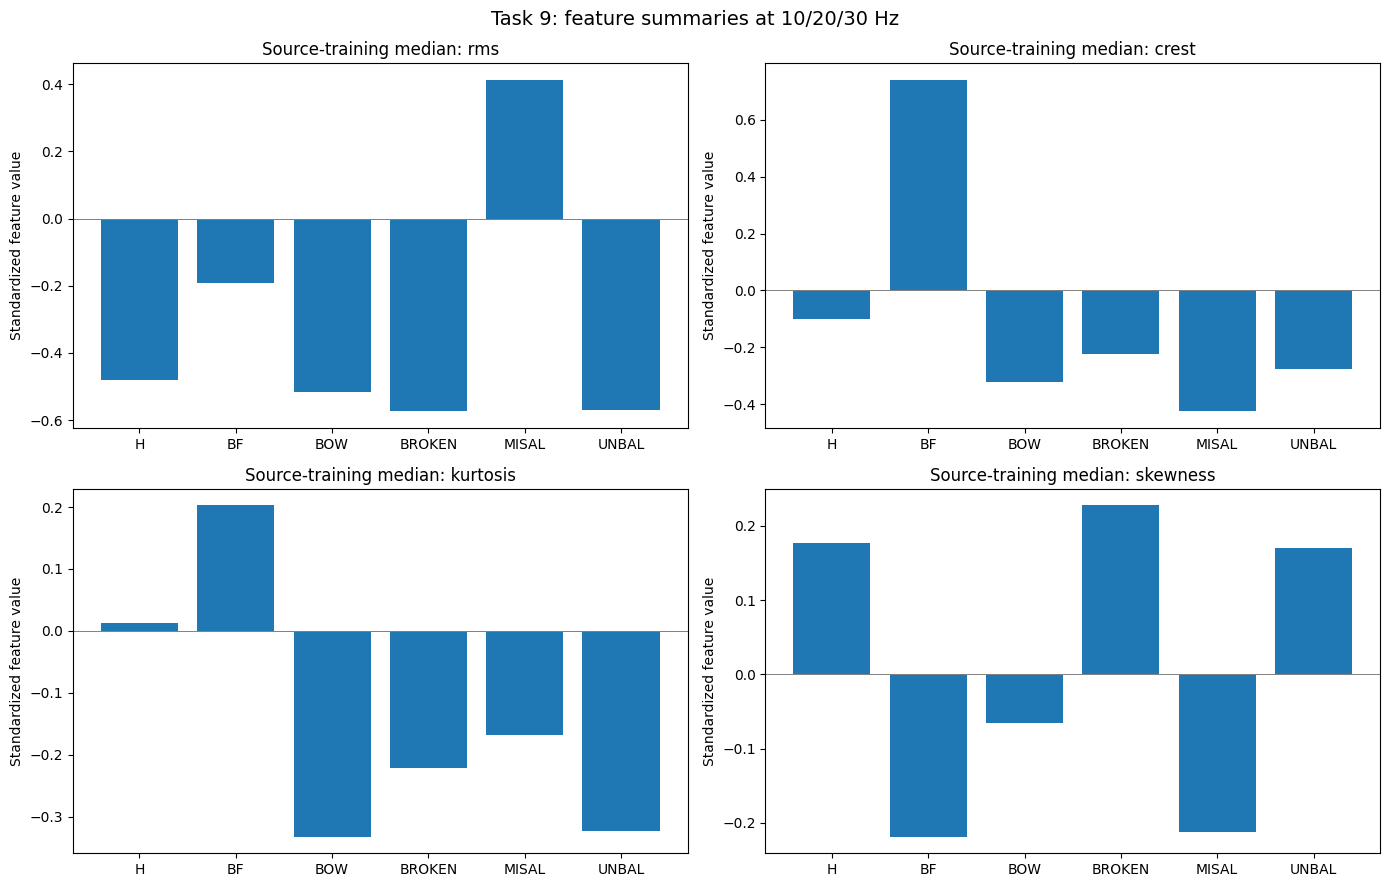

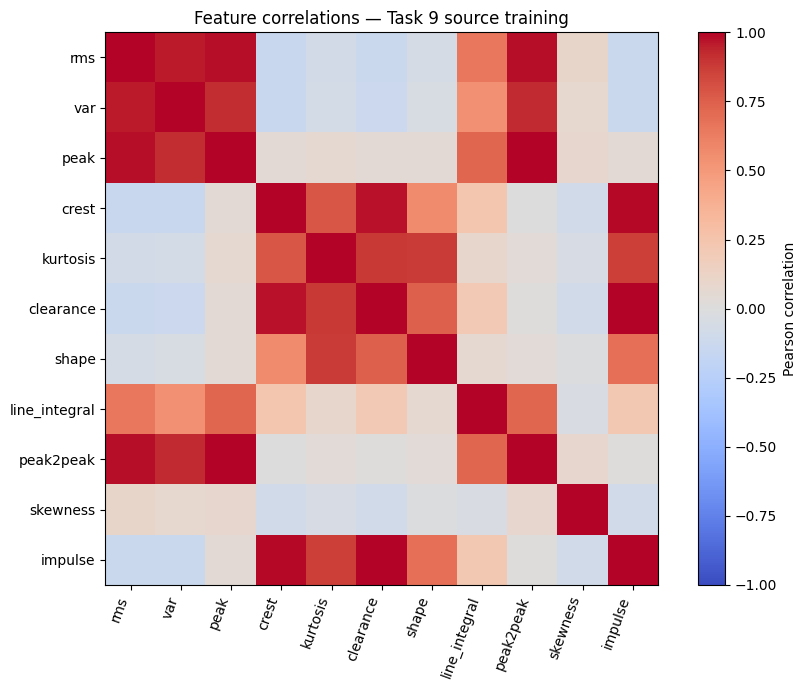

In [6]:
train_df9 = pd.DataFrame(X_train9, columns=feature_names)
train_df9["condition"] = [CLASS_NAMES[int(v)] for v in y_train9]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, name in zip(axes.flat, ["rms", "crest", "kurtosis", "skewness"]):
    medians = train_df9.groupby("condition")[name].median().reindex(CLASS_NAMES)
    ax.bar(range(6), medians.values)
    ax.set_xticks(range(6), ["H", "BF", "BOW", "BROKEN", "MISAL", "UNBAL"])
    ax.set_title(f"Source-training median: {name}")
    ax.set_ylabel("Standardized feature value")
    ax.axhline(0, color="gray", linewidth=0.7)
fig.suptitle("Task 9: feature summaries at 10/20/30 Hz", fontsize=14)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "task9_train_feature_medians.png", dpi=180)
plt.show()

corr = pd.DataFrame(X_train9, columns=feature_names).corr()
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(11), feature_names, rotation=70, ha="right")
ax.set_yticks(range(11), feature_names)
ax.set_title("Feature correlations — Task 9 source training")
fig.colorbar(im, ax=ax, label="Pearson correlation")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "task9_train_feature_correlation.png", dpi=180)
plt.show()

## 8. Train a first Random Forest on Task 9 — validation only

We predefine the model before seeing target results:

- `n_estimators=200`: 200 decision trees.
- `max_features="sqrt"`: a random subset of features considered at each split.
- `min_samples_leaf=2`: a small amount of regularization.
- `random_state=0`: reproducible seed.

**This is a fixed exploratory baseline, not a tuned or proven-optimal configuration.** Compare training and *source validation* performance. The target test set remains unused until Section 11.

Task 9 source train accuracy: 99.32%
Task 9 source validation accuracy: 70.11%

SOURCE VALIDATION — classification report:
                   precision    recall  f1-score   support

          Healthy      0.685     0.637     0.660       600
    Bearing fault      0.955     0.990     0.972       600
      Bowed rotor      0.707     0.715     0.711       600
Broken rotor bars      0.551     0.550     0.550       600
     Misalignment      0.901     0.882     0.891       600
Voltage unbalance      0.415     0.433     0.424       600

         accuracy                          0.701      3600
        macro avg      0.702     0.701     0.701      3600
     weighted avg      0.702     0.701     0.701      3600



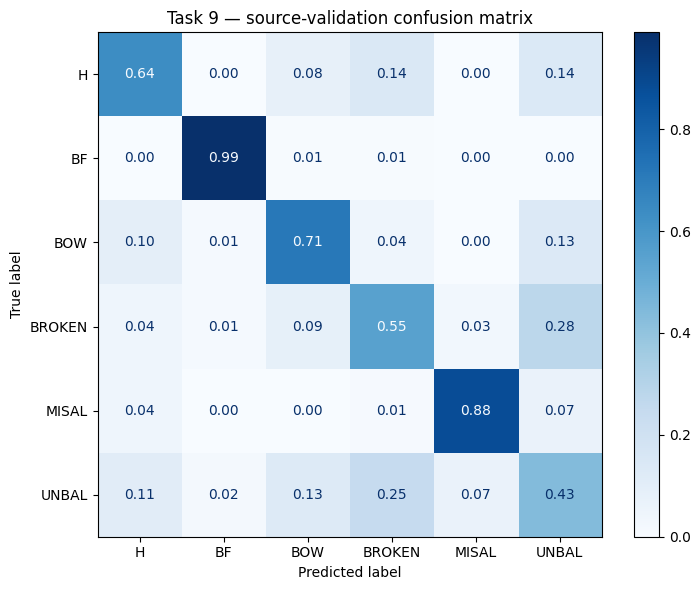

In [7]:
RF_PARAMS = dict(
    n_estimators=200,
    max_features="sqrt",
    min_samples_leaf=2,
    n_jobs=-1
)

def new_random_forest(seed):
    return RandomForestClassifier(**RF_PARAMS, random_state=int(seed))

rf_task9 = new_random_forest(seed=0)
rf_task9.fit(X_train9, y_train9)

pred_train9 = rf_task9.predict(X_train9)
pred_val9 = rf_task9.predict(X_val9)

print(f"Task 9 source train accuracy: {accuracy_score(y_train9, pred_train9)*100:.2f}%")
print(f"Task 9 source validation accuracy: {accuracy_score(y_val9, pred_val9)*100:.2f}%")
print("\nSOURCE VALIDATION — classification report:")
print(classification_report(
    y_val9, pred_val9, labels=LABELS,
    target_names=CLASS_NAMES, zero_division=0, digits=3
))

fig, ax = plt.subplots(figsize=(7.5, 6))
ConfusionMatrixDisplay.from_predictions(
    y_val9, pred_val9, labels=LABELS,
    display_labels=["H", "BF", "BOW", "BROKEN", "MISAL", "UNBAL"],
    normalize="true", values_format=".2f", cmap="Blues", ax=ax
)
ax.set_title("Task 9 — source-validation confusion matrix")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "task9_source_validation_confusion.png", dpi=180)
plt.show()

## 9. Which features does the Random Forest rely on?

We compute **permutation importance on source-validation data**. We measure how much accuracy drops when one feature is randomly shuffled. This is a diagnostic of **model reliance**, not proof of physical causality or a guarantee of target-domain transfer.

**Caution:** RMS, variance, peak and peak-to-peak can be correlated. Correlated features may appear individually unimportant because the model can substitute one for another.

Reference: [scikit-learn — permutation importance](https://scikit-learn.org/stable/modules/permutation_importance.html).

,feature,importance_mean,importance_std
7,line_integral,0.447431,0.002164
1,var,0.054097,0.002616
0,rms,0.044375,0.002110
9,skewness,0.024444,0.004049
6,shape,0.012639,0.000417
8,peak2peak,0.009375,0.001836
4,kurtosis,0.004514,0.002955
10,impulse,0.003264,0.001728
5,clearance,0.001736,0.002674
3,crest,-0.000069,0.002384


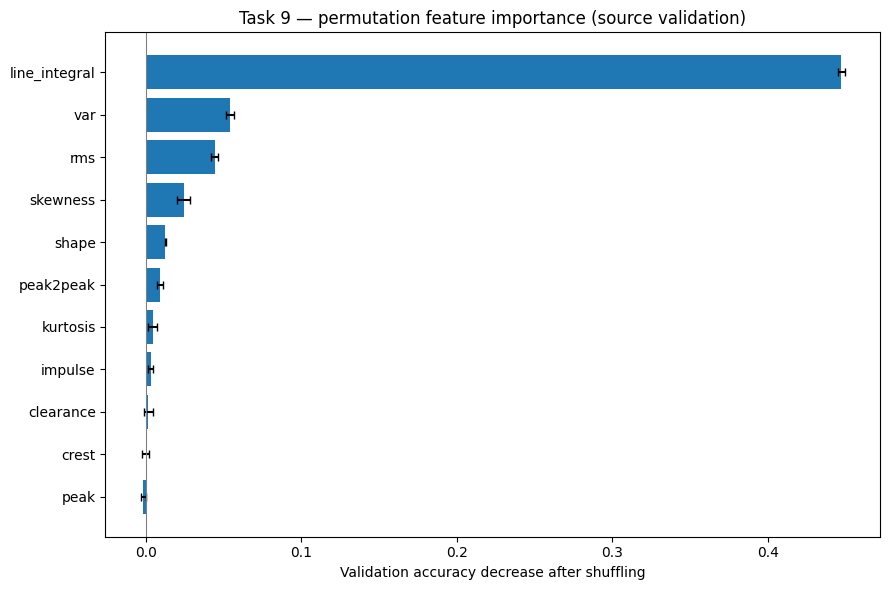

In [8]:
perm9 = permutation_importance(
    rf_task9, X_val9, y_val9,
    scoring="accuracy", n_repeats=4,
    random_state=0, n_jobs=1
)
importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance_mean": perm9.importances_mean,
    "importance_std": perm9.importances_std
}).sort_values("importance_mean", ascending=False)

importance_df.to_csv(RESULTS_DIR / "task9_source_validation_importance.csv", index=False)
display(importance_df)

plot_df = importance_df.iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(
    plot_df["feature"], plot_df["importance_mean"],
    xerr=plot_df["importance_std"], capsize=3
)
ax.axvline(0, color="gray", linewidth=0.8)
ax.set_xlabel("Validation accuracy decrease after shuffling")
ax.set_title("Task 9 — permutation feature importance (source validation)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "task9_source_validation_importance.png", dpi=180)
plt.show()

## 10. Ablation study: all, amplitude-related and shape-related features

One hypothesis suggested by the preprocessing documentation is that **amplitude-related features may be more sensitive to motor speed**, while ratio-based or shape-related descriptors may be relatively scale independent.

We predefine three feature groups:

| Group | Included features | Count |
|---|---|---:|
| All 11 | All available acoustic features | 11 |
| Amplitude | `rms`, `var`, `peak`, `line_integral`, `peak2peak` | 5 |
| Shape | `crest`, `kurtosis`, `clearance`, `shape`, `skewness`, `impulse` | 6 |

These groupings are **hypotheses**, not established guarantees of generalization. First compare them on Task 9 **source validation only**. In the next section, evaluate each predefined group on all four held-out target speeds.

In [9]:
FEATURE_GROUPS = {
    "All 11": list(feature_names),
    "Amplitude only": ["rms", "var", "peak", "line_integral", "peak2peak"],
    "Shape only": ["crest", "kurtosis", "clearance", "shape", "skewness", "impulse"]
}

def feature_indices(group):
    return [feature_names.index(name) for name in FEATURE_GROUPS[group]]

assert set(FEATURE_GROUPS["Amplitude only"]).isdisjoint(FEATURE_GROUPS["Shape only"])
assert set(FEATURE_GROUPS["Amplitude only"] + FEATURE_GROUPS["Shape only"]) == set(feature_names)

validation_rows = []
for group, members in FEATURE_GROUPS.items():
    cols = feature_indices(group)
    model = new_random_forest(seed=0)
    model.fit(X_train9[:, cols], y_train9)
    pred = model.predict(X_val9[:, cols])
    validation_rows.append({
        "group": group,
        "features": len(cols),
        "source_val_accuracy_pct": 100 * accuracy_score(y_val9, pred),
        "source_val_macro_f1": f1_score(y_val9, pred, average="macro")
    })

validation_table = pd.DataFrame(validation_rows)
validation_table.to_csv(RESULTS_DIR / "task9_validation_feature_groups.csv", index=False)
display(validation_table.round(3))

,group,features,source_val_accuracy_pct,source_val_macro_f1
0,All 11,11,70.111,0.701
1,Amplitude only,5,68.528,0.685
2,Shape only,6,29.417,0.282


## 11. Final experiment — 4 tasks × 3 predefined groups × 10 seeds

This is the main experiment. It trains **120 Random Forests**, not CNNs:

- Four target domains (Tasks 9–12)
- Three fixed feature groups
- Ten seeds (`0..9`) per group and task

The task's source-training data are used to fit each forest. Source validation and the unseen target are evaluated separately. **Nothing is tuned or selected using target accuracy.**

Outputs:

- `results/rf_feature_runs.csv`: per-seed validation/target metrics.
- `results/rf_target_confusions.npz`: row-normalized target confusion matrices for each run.
- `models/rf_all11_task*_seed0.joblib`: one saved reference forest per task (all 11 features, seed 0).
- `results/experiment_metadata.json`: data, preprocessing and model configuration.

**Usage:** Run once with `RUN_FULL_EXPERIMENT = True`. Once completed, switch it to `False` to reuse the saved CSV without retraining.

In [10]:
TASKS = [9, 10, 11, 12]
SEEDS = list(range(10))
RUN_FULL_EXPERIMENT = True  # Change to False after completing the first full run

RUNS_PATH = RESULTS_DIR / "rf_feature_runs.csv"
CONFUSIONS_PATH = RESULTS_DIR / "rf_target_confusions.npz"
METADATA_PATH = RESULTS_DIR / "experiment_metadata.json"

metadata = {
    "name": "HUSTmotor acoustic engineered features — Random Forest",
    "institution": "Université de technologie de Compiègne (UTC)",
    "dataset_name": DATA_PATH.name,
    "dataset_sha256": actual_hash,
    "preprocessing_repository": REPO_URL,
    "preprocessing_commit": actual_commit,
    "feature_source": "feat_a from HUSTmotor v1.3",
    "feature_standardization": "per-feature source-training mean/std via load_dg_task",
    "waveform_norm_argument": "zscore (waveform outputs not used)",
    "feature_names": feature_names,
    "groups": FEATURE_GROUPS,
    "random_forest_params": RF_PARAMS,
    "seeds": SEEDS,
    "tasks": TASKS,
    "target_use": "final evaluation only; no target-based tuning",
    "current_runtime": {
        "python": platform.python_version(),
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "scikit_learn": sklearn.__version__
    },
    "created_utc": datetime.now(timezone.utc).isoformat()
}
with open(METADATA_PATH, "w") as fp:
    json.dump(metadata, fp, indent=2, default=str)

if RUN_FULL_EXPERIMENT:
    rows = []
    confusions = {}

    for task_number in TASKS:
        Xtr, ytr, Xva, yva, Xte, yte, names = load_acoustic_features(task_number)
        assert names == feature_names
        print(f"\nTask {task_number} | unseen {DOMAIN_TO_SPEED[TASK_TO_DOMAIN[task_number]]}")

        for group in FEATURE_GROUPS:
            cols = feature_indices(group)
            print(f"  {group}: {len(cols)} features, {len(SEEDS)} seeds")

            for seed in SEEDS:
                model = new_random_forest(seed)
                model.fit(Xtr[:, cols], ytr)
                val_pred = model.predict(Xva[:, cols])
                target_pred = model.predict(Xte[:, cols])

                rows.append({
                    "task": task_number,
                    "target_speed": DOMAIN_TO_SPEED[TASK_TO_DOMAIN[task_number]],
                    "group": group,
                    "n_features": len(cols),
                    "seed": seed,
                    "val_accuracy_pct": 100 * accuracy_score(yva, val_pred),
                    "val_macro_f1": f1_score(yva, val_pred, average="macro", zero_division=0),
                    "target_accuracy_pct": 100 * accuracy_score(yte, target_pred),
                    "target_balanced_accuracy_pct": 100 * balanced_accuracy_score(yte, target_pred),
                    "target_macro_f1": f1_score(yte, target_pred, average="macro", zero_division=0)
                })

                key = f"task{task_number}_{group.lower().replace(' ', '_')}_seed{seed}"
                confusions[key] = confusion_matrix(
                    yte, target_pred, labels=LABELS, normalize="true"
                ).astype(np.float32)

                if group == "All 11" and seed == 0:
                    joblib.dump({
                        "model": model,
                        "task": task_number,
                        "seed": seed,
                        "features": FEATURE_GROUPS[group],
                        "dataset_sha256": actual_hash,
                        "preprocessing_commit": actual_commit
                    }, MODELS_DIR / f"rf_all11_task{task_number}_seed0.joblib")

    runs_df = pd.DataFrame(rows)
    assert len(runs_df) == len(TASKS) * len(FEATURE_GROUPS) * len(SEEDS)
    assert not runs_df.duplicated(["task", "group", "seed"]).any()
    runs_df.to_csv(RUNS_PATH, index=False)
    np.savez_compressed(CONFUSIONS_PATH, **confusions)
    print(f"\nSaved {len(runs_df)} runs to: {RUNS_PATH}")
    print("Saved target confusion matrices to:", CONFUSIONS_PATH)

else:
    if not RUNS_PATH.is_file() or not CONFUSIONS_PATH.is_file():
        raise FileNotFoundError(
            "No previous full-run results found. Set RUN_FULL_EXPERIMENT = True first."
        )
    runs_df = pd.read_csv(RUNS_PATH)
    print("Reused saved results:", RUNS_PATH)

print("Recorded runs:", len(runs_df))
display(runs_df.head())


Task 9 | unseen 5 Hz
  All 11: 11 features, 10 seeds
  Amplitude only: 5 features, 10 seeds
  Shape only: 6 features, 10 seeds

Task 10 | unseen 10 Hz
  All 11: 11 features, 10 seeds
  Amplitude only: 5 features, 10 seeds
  Shape only: 6 features, 10 seeds

Task 11 | unseen 20 Hz
  All 11: 11 features, 10 seeds
  Amplitude only: 5 features, 10 seeds
  Shape only: 6 features, 10 seeds

Task 12 | unseen 30 Hz
  All 11: 11 features, 10 seeds
  Amplitude only: 5 features, 10 seeds
  Shape only: 6 features, 10 seeds

Saved 120 runs to: /content/drive/MyDrive/HUSTmotor_Acoustic_Feature_Analysis/results/rf_feature_runs.csv
Saved target confusion matrices to: /content/drive/MyDrive/HUSTmotor_Acoustic_Feature_Analysis/results/rf_target_confusions.npz
Recorded runs: 120


,task,target_speed,group,n_features,seed,val_accuracy_pct,val_macro_f1,target_accuracy_pct,target_balanced_accuracy_pct,target_macro_f1
0,9,5 Hz,All 11,11,0,70.111111,0.701395,17.583333,17.583333,0.110067
1,9,5 Hz,All 11,11,1,69.388889,0.694400,16.916667,16.916667,0.098479
2,9,5 Hz,All 11,11,2,69.833333,0.698958,17.166667,17.166667,0.107514
3,9,5 Hz,All 11,11,3,69.555556,0.696014,16.666667,16.666667,0.102634
4,9,5 Hz,All 11,11,4,69.944444,0.699404,16.666667,16.666667,0.099350


## 12. Summarize mean ± standard deviation across 10 seeds

We report **unseen-target accuracy** as the primary metric, and show the source-validation accuracy and macro-F1 as supplementary information.

- Per-task SD: sample SD across ten Random Forest seeds.
- Overall SD: compute the mean across four tasks **for each seed**, then calculate SD across ten seed-wise means (same reporting convention as our CNN experiments).
- Random Forest seeds mainly capture randomness in constructing trees; **they do not represent ten new independent dataset splits**. These SDs are not uncertainty across recordings or acquisition sessions.

In [11]:
assert set(runs_df["task"]) == set(TASKS)
assert set(runs_df["seed"]) == set(SEEDS)
assert set(runs_df["group"]) == set(FEATURE_GROUPS)
assert runs_df.groupby(["task", "group"]).size().eq(len(SEEDS)).all()

summary_df = (
    runs_df.groupby(["group", "task", "target_speed"], as_index=False)
    .agg(
        mean_target_acc=("target_accuracy_pct", "mean"),
        sd_target_acc=("target_accuracy_pct", "std"),
        mean_val_acc=("val_accuracy_pct", "mean"),
        mean_target_macro_f1=("target_macro_f1", "mean"),
        mean_target_balanced_acc=("target_balanced_accuracy_pct", "mean")
    )
)
summary_df.to_csv(RESULTS_DIR / "rf_feature_task_summary.csv", index=False)

overall_seed = (
    runs_df.groupby(["group", "seed"], as_index=False)
    .agg(seed_mean_target_accuracy=("target_accuracy_pct", "mean"))
)
overall_summary = (
    overall_seed.groupby("group", as_index=False)
    .agg(
        overall_mean_accuracy=("seed_mean_target_accuracy", "mean"),
        overall_sd_accuracy=("seed_mean_target_accuracy", "std")
    )
)
overall_summary.to_csv(RESULTS_DIR / "rf_feature_overall_summary.csv", index=False)

print("TARGET ACCURACY BY TASK (percentage):")
display(summary_df.round(2))
print("OVERALL TARGET ACCURACY (percentage):")
display(overall_summary.round(2))

TARGET ACCURACY BY TASK (percentage):


,group,task,target_speed,mean_target_acc,sd_target_acc,mean_val_acc,mean_target_macro_f1,mean_target_balanced_acc
0,All 11,9,5 Hz,17.11,0.37,69.74,0.10,17.11
1,All 11,10,10 Hz,6.23,0.91,76.72,0.05,6.23
2,All 11,11,20 Hz,2.68,0.33,72.99,0.01,2.68
3,All 11,12,30 Hz,16.76,0.03,65.22,0.11,16.76
4,Amplitude only,9,5 Hz,20.78,0.38,68.40,0.13,20.78
5,Amplitude only,10,10 Hz,8.63,0.63,75.03,0.05,8.63
6,Amplitude only,11,20 Hz,2.53,0.06,71.60,0.01,2.53
7,Amplitude only,12,30 Hz,0.08,0.00,65.07,0.00,0.08
8,Shape only,9,5 Hz,17.94,0.53,29.43,0.18,17.94
9,Shape only,10,10 Hz,22.86,0.50,30.92,0.22,22.86


OVERALL TARGET ACCURACY (percentage):


,group,overall_mean_accuracy,overall_sd_accuracy
0,All 11,10.69,0.22
1,Amplitude only,8.01,0.18
2,Shape only,21.92,0.23


## 13. Plot feature-group results and compare with the two CNN baselines

Reference CNN values are copied from the completed notebook results. They **do not** imply that the Random Forest uses the CNN or that its accuracy must exceed the CNN's.

- Z-score CNN: **48.45%** overall mean.
- RMS CNN: **38.19%** overall mean.

**Interpretation caution:** The original z-score CNN used v1.0 and the RMS CNN and RF use v1.3; the shared preprocessing docs report identical underlying signals/splits, but exact experimental equivalence should be verified before attributing performance differences to one choice alone. The CNN and Random Forest also differ in architecture and input representation.

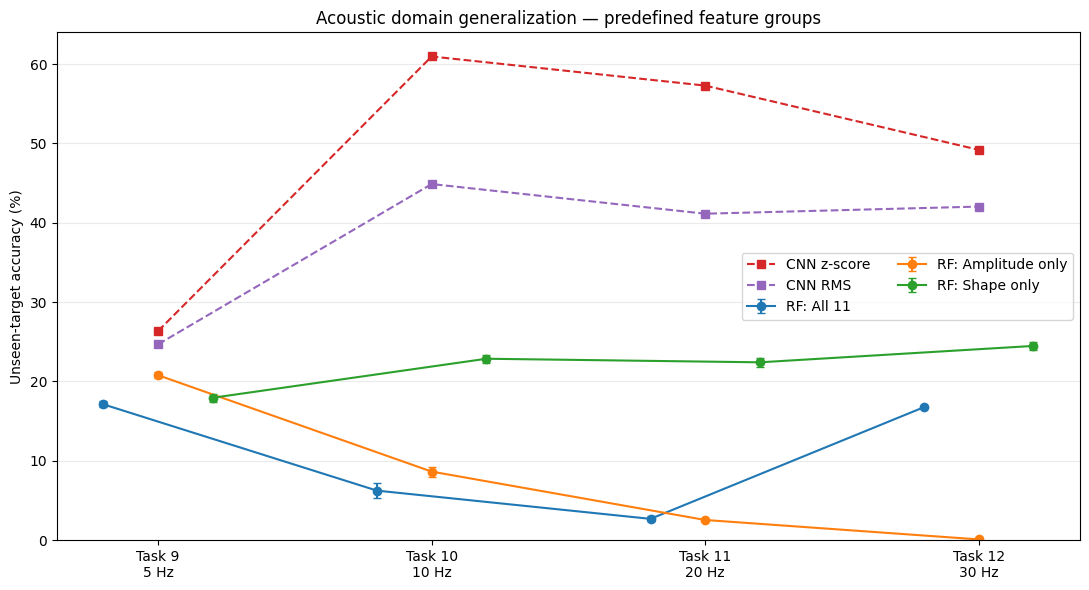

RF overall mean ± SD:
  All 11: 10.69 ± 0.22%
  Amplitude only: 8.01 ± 0.18%
  Shape only: 21.92 ± 0.23%


In [12]:
CNN_BASELINES = {
    "CNN z-score": {9: 26.36, 10: 60.96, 11: 57.29, 12: 49.19},
    "CNN RMS": {9: 24.68, 10: 44.88, 11: 41.14, 12: 42.04}
}

fig, ax = plt.subplots(figsize=(11, 6))
x = np.arange(len(TASKS))
for offset, group in zip([-0.20, 0, 0.20], FEATURE_GROUPS):
    sub = summary_df[summary_df["group"] == group].set_index("task").loc[TASKS]
    ax.errorbar(
        x + offset, sub["mean_target_acc"],
        yerr=sub["sd_target_acc"], marker="o", capsize=3,
        linestyle="-", label=f"RF: {group}"
    )
for name, values in CNN_BASELINES.items():
    ax.plot(x, [values[t] for t in TASKS], linestyle="--", marker="s", label=name)
ax.set_xticks(x, [f"Task {t}\n{DOMAIN_TO_SPEED[TASK_TO_DOMAIN[t]]}" for t in TASKS])
ax.set_ylim(bottom=0)
ax.set_ylabel("Unseen-target accuracy (%)")
ax.set_title("Acoustic domain generalization — predefined feature groups")
ax.legend(ncol=2)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "rf_feature_groups_vs_cnn.png", dpi=200)
plt.show()

print("RF overall mean ± SD:")
for _, row in overall_summary.iterrows():
    print(f"  {row['group']}: {row['overall_mean_accuracy']:.2f} ± {row['overall_sd_accuracy']:.2f}%")

## 14. Target-domain confusion matrices (all 11 features)

After the predefined models have been evaluated, inspect **which classes are misclassified** at each unseen speed. These are post-hoc diagnostics, not a basis for retuning the already evaluated models on the same target.

Each matrix is row-normalized and averaged over the 10 seeds for the **All 11** feature group.

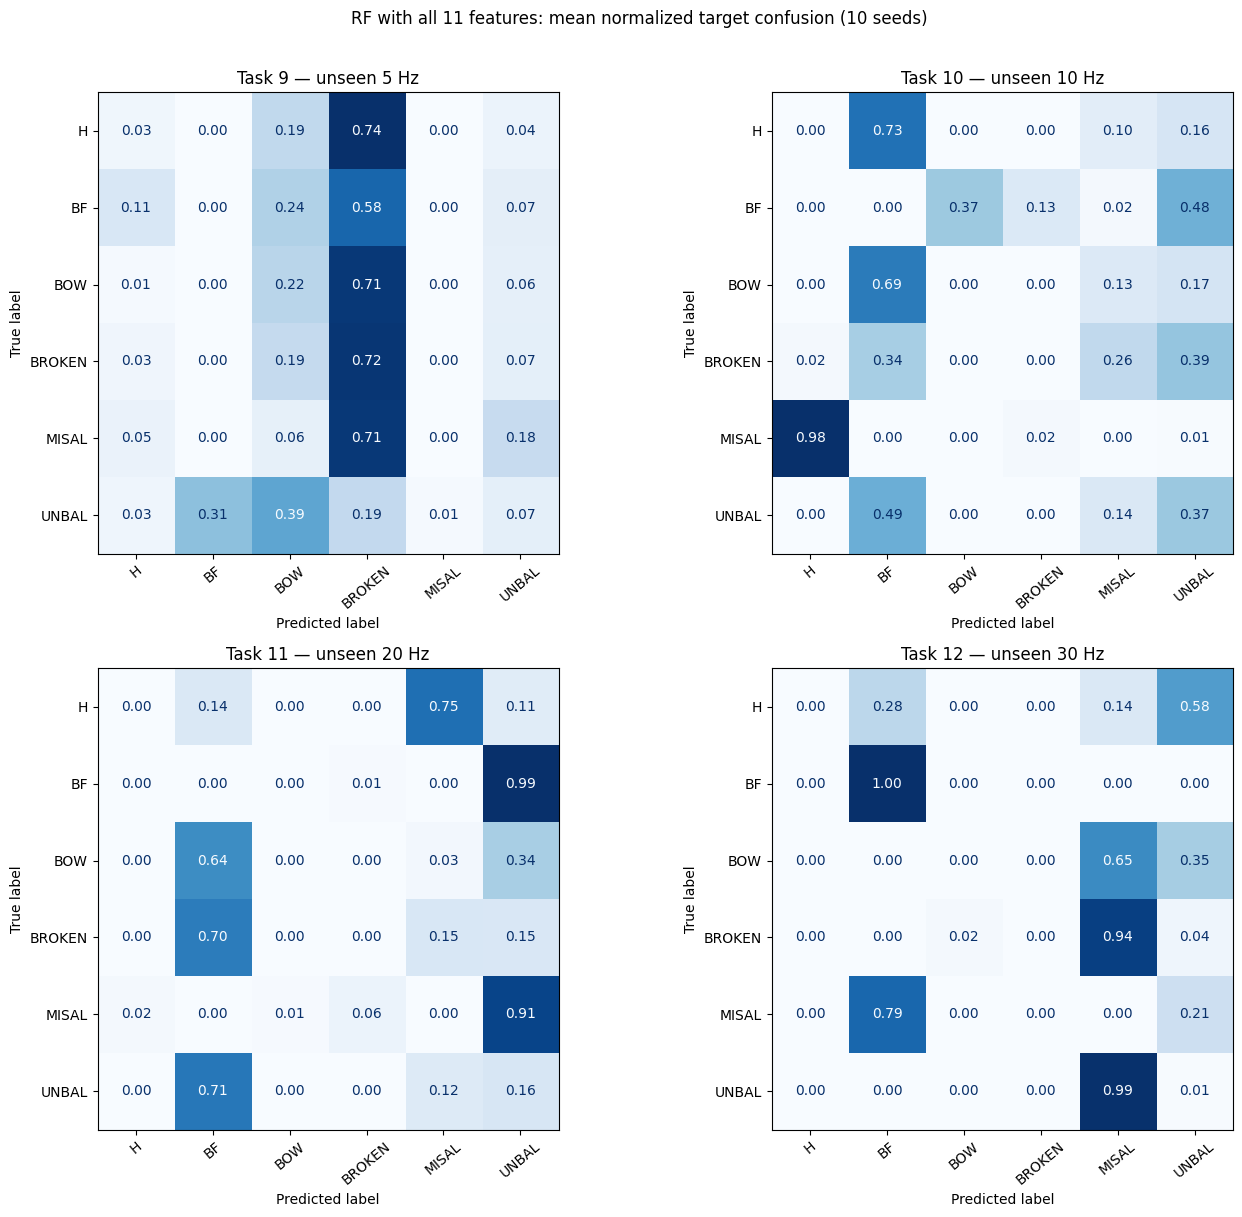

In [13]:
short_labels = ["H", "BF", "BOW", "BROKEN", "MISAL", "UNBAL"]
with np.load(CONFUSIONS_PATH) as stored:
    fig, axes = plt.subplots(2, 2, figsize=(14, 12))
    for ax, task in zip(axes.flat, TASKS):
        stack = np.stack([
            stored[f"task{task}_all_11_seed{seed}"] for seed in SEEDS
        ])
        mean_cm = stack.mean(axis=0)
        disp = ConfusionMatrixDisplay(mean_cm, display_labels=short_labels)
        disp.plot(ax=ax, cmap="Blues", values_format=".2f", colorbar=False)
        ax.set_title(f"Task {task} — unseen {DOMAIN_TO_SPEED[TASK_TO_DOMAIN[task]]}")
        ax.tick_params(axis="x", labelrotation=40)
    fig.suptitle("RF with all 11 features: mean normalized target confusion (10 seeds)", y=1.01)
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / "rf_all11_target_confusions.png", dpi=200, bbox_inches="tight")
    plt.show()

## 15. Research interpretation and next steps

### How to read the results

**A. If source-validation accuracy is high but target accuracy is low:** the feature relationships may be predictive at familiar speeds but change at the unseen speed. This is a domain-generalization problem, not necessarily a model implementation bug.

**B. If shape-only beats amplitude-only on unseen speeds:** that supports the hypothesis that scale-independent descriptors transfer better. Report all tasks (not only the most favorable one) and remember that the feature groups contain different numbers of descriptors.

**C. If engineered-feature RF beats the CNN:** features may offer a compact alternative representation, but this **does not prove** that adding them to the CNN will improve the CNN. That requires a separate, controlled feature-fusion ablation.

**D. If engineered-feature RF performs poorly:** the statistical descriptors may be insufficient or speed-dependent; it does not mean the raw waveform has no useful information.

### Proposed follow-up (not implemented here)

A *feature-level fusion* model could take:

```text
Acoustic waveform (1 × 1024) ──> Existing 1D CNN ──> learned embedding ─┐
                                                                         ├─ concatenate ─> MLP ─> 6 classes
11 engineered acoustic features ─────> small MLP ────> feature embedding ─┘
```

This is **not** “Random Forest preprocessing.” The neural network receives the **original engineered features** in a separate branch. Random Forest is used here to benchmark and study their potential value.

### Scientific cautions

- The data have overlapping windows within acquisition blocks. Even with separated blocks, neighboring samples are correlated; the nominal sample count is not the number of independent recordings.
- Models share identical train/validation/test partitions across seeds. RF seed variability should not be interpreted as uncertainty across entirely new recording sessions.
- Selection of the "best" feature group based on reported target performance would turn the target into a development set. Use a new held-out setting or source-only selection criteria before claiming generalization of a chosen design.
- Importance rankings can be distorted by correlated features and only describe **this fitted Random Forest on the specified validation distribution**.

### Files produced in Google Drive

```text
HUSTmotor_Acoustic_Feature_Analysis/
├── data/                       # only if a new dataset download was necessary
├── results/
│   ├── experiment_metadata.json
│   ├── task9_source_validation_importance.csv
│   ├── task9_validation_feature_groups.csv
│   ├── rf_feature_runs.csv
│   ├── rf_target_confusions.npz
│   ├── rf_feature_task_summary.csv
│   └── rf_feature_overall_summary.csv
├── figures/
│   ├── task9_train_feature_medians.png
│   ├── task9_train_feature_correlation.png
│   ├── task9_source_validation_confusion.png
│   ├── task9_source_validation_importance.png
│   ├── rf_feature_groups_vs_cnn.png
│   └── rf_all11_target_confusions.png
└── models/
    └── rf_all11_task{9,10,11,12}_seed0.joblib
```

### References

1. Zhao, C., Shen, W., Zio, E., & Ma, H. (2025). *Multimodal unified generalization and translation network for intelligent fault diagnosis under dynamic environments*. Engineering Applications of Artificial Intelligence, 162, 112559. https://doi.org/10.1016/j.engappai.2025.112559
2. [Genti24-bit/ISCF_Project, `USAGE.md`, §11: Time-domain features](https://github.com/Genti24-bit/ISCF_Project/blob/main/USAGE.md) and [`preprocess_hustmotor.py`](https://github.com/Genti24-bit/ISCF_Project/blob/main/preprocess_hustmotor.py). The loader references Tran et al., *Mathematics* **12** (2024), 1569, Table 2 for the feature definitions.
3. Breiman, L. (2001). *Random Forests*. Machine Learning, 45, 5–32. https://doi.org/10.1023/A:1010933404324
4. [scikit-learn: permutation importance and correlation caveats](https://scikit-learn.org/stable/modules/permutation_importance.html)